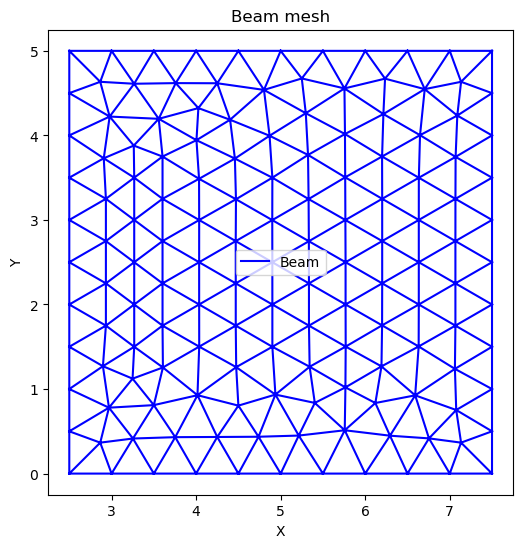

Step 1: R_sum -2.03, Max Kappa 0.000000
Step 2: R_sum -4.07, Max Kappa 0.000000
Step 3: R_sum -6.10, Max Kappa 0.000000
Step 4: R_sum -8.13, Max Kappa 0.000000
Step 5: R_sum -10.16, Max Kappa 0.000000
Step 6: R_sum -12.20, Max Kappa 0.000000
Step 7: R_sum -14.23, Max Kappa 0.000000
Step 8: R_sum -16.26, Max Kappa 0.000000
Step 9: R_sum -18.29, Max Kappa 0.000000
Step 10: R_sum -20.33, Max Kappa 0.000000
Step 11: R_sum -22.36, Max Kappa 0.000000
Step 12: R_sum -24.39, Max Kappa 0.000000
Step 13: R_sum -26.42, Max Kappa 0.000000
Step 14: R_sum -28.46, Max Kappa 0.000000
Step 15: R_sum -30.49, Max Kappa 0.000000
Step 16: R_sum -32.52, Max Kappa 0.000000
Step 17: R_sum -34.55, Max Kappa 0.000000
Step 18: R_sum -36.59, Max Kappa 0.000000
Step 19: R_sum -38.62, Max Kappa 0.000000
Step 20: R_sum -40.65, Max Kappa 0.000000
Step 21: R_sum -42.69, Max Kappa 0.000000
Step 22: R_sum -44.72, Max Kappa 0.000000
Step 23: R_sum -46.75, Max Kappa 0.000000
Step 24: R_sum -48.78, Max Kappa 0.000000
Step 

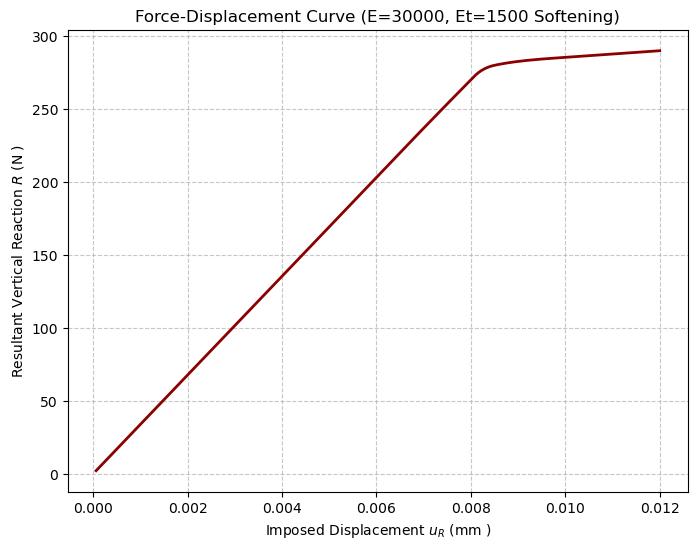

In [ ]:
import gmsh
import numpy as np
import matplotlib.pyplot as plt
import os

# --- GMSH MESHING---
gmsh.initialize()
gmsh.model.add("beam_only")
# Mesh size
lc = 0.5 #[mm]

# Beam geometry 
beam_width  = 5     # width in x [mm]
beam_height = 5    # height in y [mm]

xL = beam_width- beam_width/2   # left x
xR = beam_width + beam_width/2   # right x
yB = 0.0                  # bottom
yT = beam_height          # top

# Points (counter-clockwise)
p1 = gmsh.model.geo.addPoint(xL, yB, 0, lc, 1)
p2 = gmsh.model.geo.addPoint(xR, yB, 0, lc, 2)
p3 = gmsh.model.geo.addPoint(xR, yT, 0, lc, 3)
p4 = gmsh.model.geo.addPoint(xL, yT, 0, lc, 4)

# Lines
l1 = gmsh.model.geo.addLine(1, 2)
l2 = gmsh.model.geo.addLine(2, 3)
l3 = gmsh.model.geo.addLine(3, 4)
l4 = gmsh.model.geo.addLine(4, 1)

# Surface
loop_beam = gmsh.model.geo.addCurveLoop([l1, l2, l3, l4])
surf_beam = gmsh.model.geo.addPlaneSurface([loop_beam], 1)

gmsh.model.geo.synchronize()

# Physical group for the beam
gmsh.model.addPhysicalGroup(2, [surf_beam], 1)
gmsh.model.setPhysicalName(2, 1, "Beam")

# Mesh
gmsh.option.setNumber("Mesh.ElementOrder", 1)
gmsh.option.setNumber("Mesh.Algorithm", 6)
gmsh.model.mesh.generate(2)

gmsh.write("beam_only.msh")
gmsh.finalize()


# VISUALIZATION OF THE MESH USING MATPLOTLIB
gmsh.initialize()
gmsh.open("beam_only.msh")   
# Nodes
node_tags, node_coords, _ = gmsh.model.mesh.getNodes()
node_coords = np.array(node_coords).reshape(-1, 3)

def get_elements_of_physical_group(dim, tag):
    entity_tags = gmsh.model.getEntitiesForPhysicalGroup(dim, tag)
    all_elements = []
    for entity_tag in entity_tags:
        elem_types, elem_tags, elem_node_tags = gmsh.model.mesh.getElements(dim, entity_tag)
        for i in range(len(elem_types)):
            all_elements.append(np.array(elem_node_tags[i]).reshape(-1, 3))
    return np.concatenate(all_elements) if all_elements else np.array([])

elements_beam = get_elements_of_physical_group(2, 1)



plt.figure(figsize=(6, 8))
if elements_beam.size > 0:
    plt.triplot(
        node_coords[:, 0],
        node_coords[:, 1],
        elements_beam - 1,
        color='blue',
        label='Beam'
    )

plt.gca().set_aspect('equal')
plt.title('Beam mesh')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show()



def jacobian(coord):
    return np.abs((coord[0,0]-coord[0,2]) * (coord[1,1]-coord[1,2]) - (coord[0,1] - coord[0,2]) * (coord[1,0] - coord[1,2]))

def B_matrix(coord):
    x1, x2, x3 = coord[0]; y1, y2, y3 = coord[1]
    A2 = x1*(y2 - y3) + x2*(y3 - y1) + x3*(y1 - y2)
    dNdx = np.array([(y2 - y3) / A2, (y3 - y1) / A2, (y1 - y2) / A2 ])
    dNdy = np.array([(x3 - x2) / A2, (x1 - x3) / A2, (x2 - x1) / A2])
    B = np.zeros((3, 6))
    B[0, 0::2] = dNdx; B[1, 1::2] = dNdy; B[2, 0::2] = dNdy; B[2, 1::2] = dNdx
    return B

def D_matrix(E, nu): 
    # Plane Strain D matrix
    coef = E / ((1.0 + nu)*(1.0 - 2.0*nu))
    return coef * np.array([
        [1.0 - nu, nu, 0.0],
        [nu, 1.0 - nu, 0.0],
        [0.0, 0.0, 0.5*(1.0 - 2.0*nu)]])

def deviatoric_part(stress_vector, nu):
    sigma_x, sigma_y, tau_xy = stress_vector
    sigma_z = nu * (sigma_x + sigma_y)
    p = (sigma_x + sigma_y + sigma_z) / 3.0
    return np.array([sigma_x - p, sigma_y - p, tau_xy])

def calculate_von_mises_stress(stress_vector, nu):
    sigma_x, sigma_y, tau_xy = stress_vector
    sigma_z = nu * (sigma_x + sigma_y)
    return np.sqrt(
        sigma_x**2 + sigma_y**2 + sigma_z**2 
        - sigma_x * sigma_y - sigma_y * sigma_z - sigma_z * sigma_x
        + 3 * tau_xy**2 )

def yield_function_plasticity(sigma_eq_tr, kappa_val, sigma_y0_val, H_val):
    return sigma_eq_tr - (sigma_y0_val + H_val * kappa_val)

def compute_Cep(C, stress_vector, H_val, nu_val, E_val):
    s = deviatoric_part(stress_vector, nu_val)
    if np.linalg.norm(s) < 1e-12: return C
    
    sigma_eq = calculate_von_mises_stress(stress_vector, nu_val)
    n_vec = 1.5 * s / sigma_eq
    n = n_vec.reshape(3, 1) 
    
    G_val = E_val / (2.0 * (1.0 + nu_val)) 
    H_star = 3.0 * G_val + H_val 
    
    Cep = C - (C @ n @ n.T @ C) / (n.T @ C @ n + H_star)
    return Cep


num_nodes = len(node_coords); n_elem = len(elements_beam)
num_dofs = 2 * num_nodes; 
max_iter = 300

# Material parameters 
E  = 30e3; nu = 0.3; sigma_y0 = 50.0
G  = E / (2.0 * (1.0 + nu))
Et = -E / 20  
H  = E * Et / (E - Et) #linear softening
D_el = D_matrix(E, nu)

# State Variables 
U = np.zeros(num_dofs)
kappa = np.zeros(n_elem)
current_stress_per_element = np.zeros((n_elem, 3))
current_strain_per_element = np.zeros((n_elem, 3))

# Boundary Condition and DOF setup 
y_coords = node_coords[:, 1]
y_max = y_coords.max(); y_min = y_coords.min()
tol = 1e-8
top_nodes = np.where(np.isclose(y_coords, y_max, atol=tol))[0]
bottom_nodes = np.where(np.isclose(y_coords, y_min, atol=tol))[0]

disp_dofs = 2 * top_nodes + 1      
bottom_x_dofs = 2 * bottom_nodes
bottom_y_dofs = 2 * bottom_nodes + 1
fixed_dofs = np.concatenate((bottom_x_dofs, bottom_y_dofs)) # Clamped end

free_dofs = np.setdiff1d(np.arange(num_dofs), np.union1d(fixed_dofs, disp_dofs))

# Load Control 
u_max = -0.012
num_steps = 200
sum_R = np.zeros(num_steps); sum_du = np.zeros(num_steps)

# --- MAIN SOLUTION LOOP (Incremental Newton-Raphson) ---

for step in range(num_steps):
    
    kappa_prev = kappa.copy(); sigma_prev = current_stress_per_element.copy(); eps_prev = current_strain_per_element.copy()
    # Imposed displacement
    u_step = u_max * (step + 1) / num_steps
    U[fixed_dofs] = 0.0; U[disp_dofs]  = u_step

    iter = 0
    
    while iter < max_iter:
        K = np.zeros((num_dofs, num_dofs)); R = np.zeros(num_dofs) # R = -F_int

        for e in range(n_elem):
            # Element setup
            n1, n2, n3 = (elements_beam[e] - 1).astype(int)
            element_coord = np.array([[node_coords[n1, 0], node_coords[n2, 0], node_coords[n3, 0]], [node_coords[n1, 1], node_coords[n2, 1], node_coords[n3, 1]]])
            B_e = B_matrix(element_coord); A = jacobian(element_coord) / 2.0
            edof = np.array([2*n1, 2*n1 + 1, 2*n2, 2*n2 + 1, 2*n3, 2*n3 + 1])
            u_e = U[edof]
            
            # --- 1. ELASTIC PREDICTOR ---
            eps_e = B_e @ u_e 
            Delta_eps = eps_e - eps_prev[e] 
            sigma_trial_vector = sigma_prev[e] + D_el @ Delta_eps
            
            sigma_eq_tr = calculate_von_mises_stress(sigma_trial_vector, nu)
            f_tr = yield_function_plasticity(sigma_eq_tr, kappa_prev[e], sigma_y0, H) 

            # --- 2. RETURN MAPPING (Plastic Corrector) ---
            if f_tr <= 1e-8: # Elastic step
                sigma_new_vector = sigma_trial_vector
                kappa_new = kappa_prev[e]
                Cep = D_el
                #print(f"Von Mises Trial Stress: {sigma_eq_tr:.1f} vs. Yield Stress: {sigma_y0 + kappa_prev[e]*H:.1f}")
            else:
                S_tr_vector = deviatoric_part(sigma_trial_vector, nu)
                n_vec = 1.5 * S_tr_vector / sigma_eq_tr
                dgamma = f_tr / (3.0 * G + H)
                sigma_new_vector = sigma_trial_vector - 2.0 * G * dgamma * n_vec
                kappa_new = kappa_prev[e] + np.sqrt(2/3) * dgamma
                Cep = compute_Cep(D_el, sigma_new_vector, H, nu, E)


            kappa[e] = kappa_new
            current_stress_per_element[e] = sigma_new_vector
            
            f_int_e = B_e.T @ sigma_new_vector * A
            Ke = B_e.T @ Cep @ B_e * A
            
            # Assemble R and K 
            for i_local in range(6):
                I_global = edof[i_local]
                R[I_global] -= f_int_e[i_local]
                
                
                for j_local in range(6):
                    J_global = edof[j_local] 
                    K[I_global, J_global] += Ke[i_local, j_local]

        # --- Solve and Update U ---
        K_ff = K[np.ix_(free_dofs, free_dofs)]
        R_f = R[free_dofs]
        
        delta_U = np.zeros_like(U)
        
        try:
             delta_U[free_dofs] = np.linalg.solve(K_ff, R_f)
        except np.linalg.LinAlgError:
             print("ERROR: Singular matrix detected. Stopping iteration.")
             break
             
        # Update U
        U[free_dofs] += delta_U[free_dofs]
        U[fixed_dofs] = 0.0 # Re-enforce
        U[disp_dofs]  = u_step # Re-enforce
        
        # res_norm defined here to see if we reach convergence
        res_norm = np.linalg.norm(delta_U[free_dofs]) 

        if res_norm < 1e-6: break
        iter += 1
        
    # --- FINAL ASSEMBLY AND REACTION CALCULATION ---
    
    if iter < max_iter:
        R_final = np.zeros(num_dofs)
        for e in range(n_elem):
            n1, n2, n3 = (elements_beam[e] - 1).astype(int); edof = np.array([2*n1, 2*n1 + 1, 2*n2, 2*n2 + 1, 2*n3, 2*n3 + 1])
            element_coord = np.array([[node_coords[n1, 0], node_coords[n2, 0], node_coords[n3, 0]], [node_coords[n1, 1], node_coords[n2, 1], node_coords[n3, 1]]])
            B_e = B_matrix(element_coord); A = jacobian(element_coord) / 2.0
            f_int_e = B_e.T @ current_stress_per_element[e] * A
            for i_local in range(6): R_final[edof[i_local]] -= f_int_e[i_local]
                
            current_strain_per_element[e] = B_e @ U[edof]
            
        # Store Reaction Force
        resultant_vertical_reaction = np.sum(R_final[bottom_y_dofs])
        
        sum_R[step] = resultant_vertical_reaction
        sum_du[step] = u_step
        print(f"Step {step+1}: R_sum {resultant_vertical_reaction:.2f}, Max Kappa {kappa.max():.6f}")

    else:
        print(f"WARNING: Step {step+1} failed to converge after {max_iter} iterations. Stopping simulation.")
        sum_R = sum_R[:step]; sum_du = sum_du[:step]; break

# --- PLOTTING ---
plt.figure(figsize=(8, 6)); 
plt.plot(abs(sum_du), abs(sum_R), color='darkred', linewidth=2); 
plt.title(f'Force-Displacement Curve (E={E:.0f}, Et={Et:.0f} Softening)'); 
plt.xlabel('Imposed Displacement $u_R$ (mm )');
plt.ylabel('Resultant Vertical Reaction $R$ (N )');
plt.grid(True, linestyle='--', alpha=0.7);
plt.show()

CREATION OF EXCEL FILES TO STORE THE RESULTS FOR DIFFERENT MESH

In [18]:
# --- FINAL ASSEMBLY AND CALCULATION OF FINAL RESULTS ---

import pandas as pd
sigma_eq_final = np.zeros(n_elem)
for e in range(n_elem):
    sigma_eq_final[e] = calculate_von_mises_stress(current_stress_per_element[e], nu)

# --- Convert arrays to DataFrames ---
dofs_per_node = 2
U_nodes = U.reshape(num_nodes, dofs_per_node) # [ux, uy] per node
node_ids = np.arange(1, num_nodes + 1)
elem_ids = np.arange(1, n_elem + 1)

# ---------- NODES (coordinates + final displacement) ----------
df_nodes = pd.DataFrame({
    "node_id": node_ids,
    "x": node_coords[:, 0],
    "y": node_coords[:, 1],
    "ux": U_nodes[:, 0],
    "uy": U_nodes[:, 1],})

# ---------- ELEMENTS (connectivity) ----------
df_elements = pd.DataFrame(
    np.column_stack([elem_ids, elements_beam]),
    columns=["elem_id", "n1", "n2", "n3"] )

# ---------- ELEMENT RESULTS (final stress state) ----------
df_elem_stress = pd.DataFrame(current_stress_per_element, columns=['sigma_x', 'sigma_y', 'tau_xy'])
df_elem_stress.insert(0, "elem_id", elem_ids)

df_vm = pd.DataFrame({
    "elem_id": elem_ids,
    "von_mises": sigma_eq_final })


df_resultant_force = pd.DataFrame(
    np.column_stack([sum_du, sum_R]),
    columns=["Imposed U", "Resultant R"]) 

df_kappa = pd.DataFrame(
    np.column_stack([kappa]),
    columns=["kappa"]) 



# ---------- SAVE EVERYTHING TO ONE EXCEL FILE ----------
filename = f"FEM_results_u0012_hardening_lc_{lc}.xlsx"

with pd.ExcelWriter(filename, engine="openpyxl") as writer:
    df_nodes.to_excel(writer, sheet_name="Nodes", index=False)
    df_elements.to_excel(writer, sheet_name="Elements", index=False)
    df_elem_stress.to_excel(writer, sheet_name="Element_Stresses", index=False)
    df_vm.to_excel(writer, sheet_name="Von_Mises", index=False)
    df_resultant_force.to_excel(writer, sheet_name="Load_Displacement", index=False)
    df_kappa.to_excel(writer, sheet_name="Kappa", index=False)

print(f"\n--- Data saved successfully to {filename} ---")


--- Data saved successfully to FEM_results_u0012_hardening_lc_0.5.xlsx ---


PLOT VON MISES 

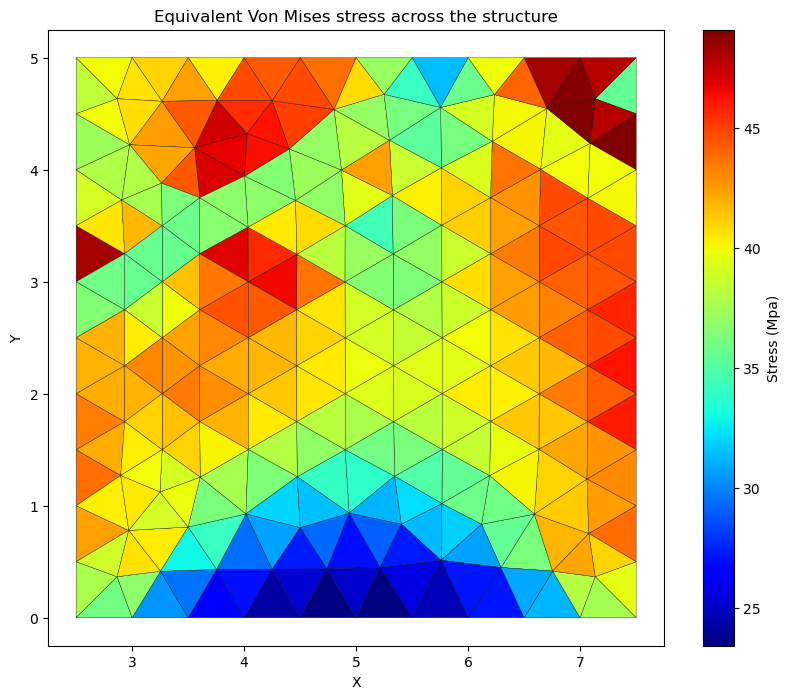

In [ ]:
import matplotlib.tri as tri
###PLOT OF VON MISES STRESS FIELDS ACROSS THE STRUCTURE
von_mises=np.array([calculate_von_mises_stress(current_stress_per_element[e], nu) for e in range(n_elem)])
def visualize_element_stress(node_coords, elements_list, stress_list):
   
    combined_elements = np.vstack([elements - 1 for elements in elements_list])
    combined_stress = np.hstack(stress_list)
    triang = tri.Triangulation(node_coords[:, 0], node_coords[:, 1], combined_elements)

    # Plot the stress distribution on elements
    plt.figure(figsize=(10, 8))
    plt.tripcolor(triang, facecolors=combined_stress, edgecolors='k', cmap='jet')
    plt.colorbar(label='Stress (Mpa)')
    plt.gca().set_aspect('equal')
    plt.title('Equivalent Von Mises stress across the structure')
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.show()

visualize_element_stress(node_coords[:, :2], elements_beam, von_mises)



VISUALISATION OF RESULTS FOR SOFTENING 

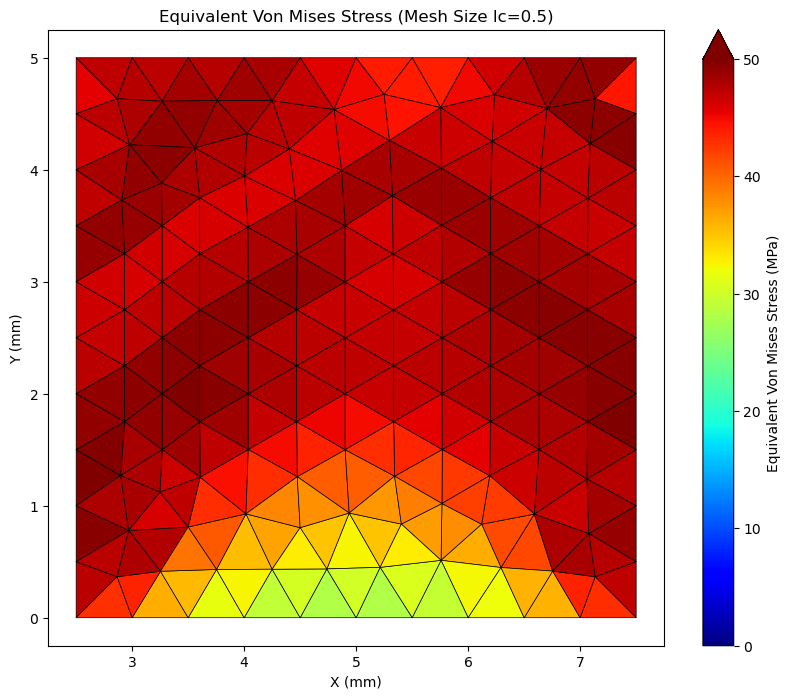

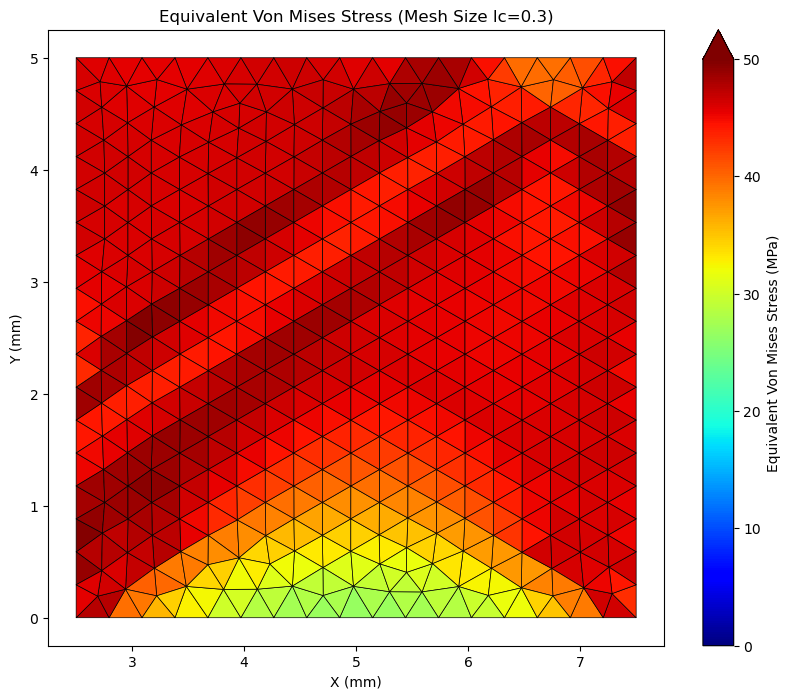

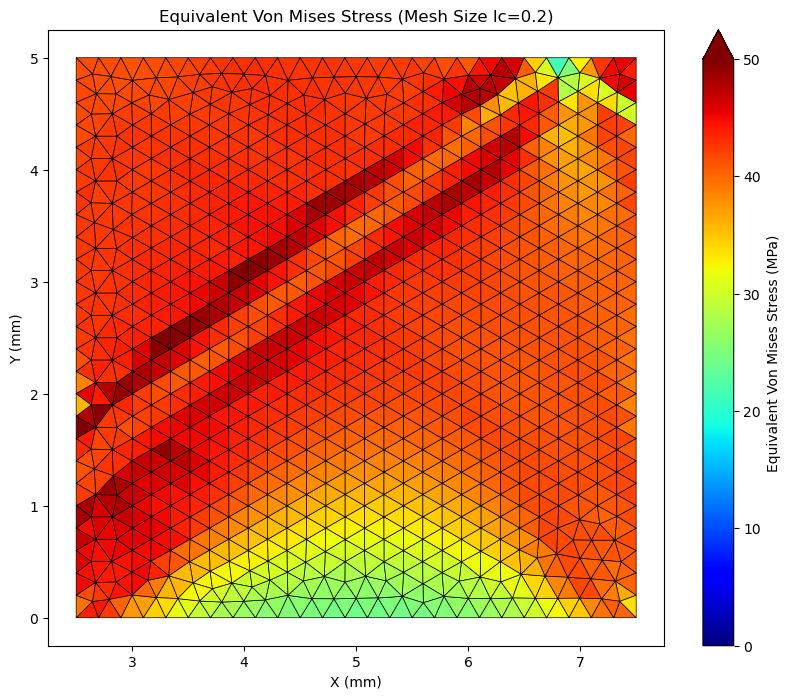

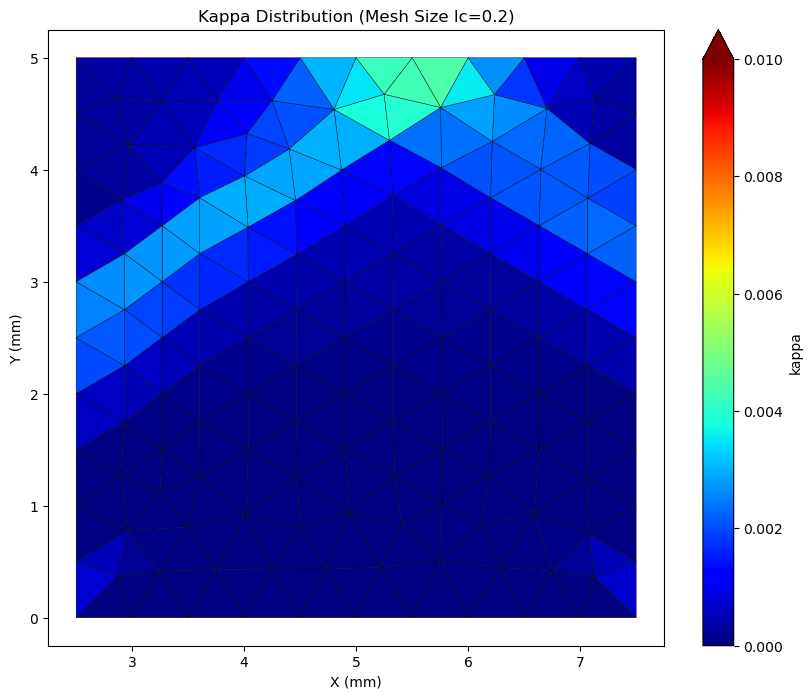

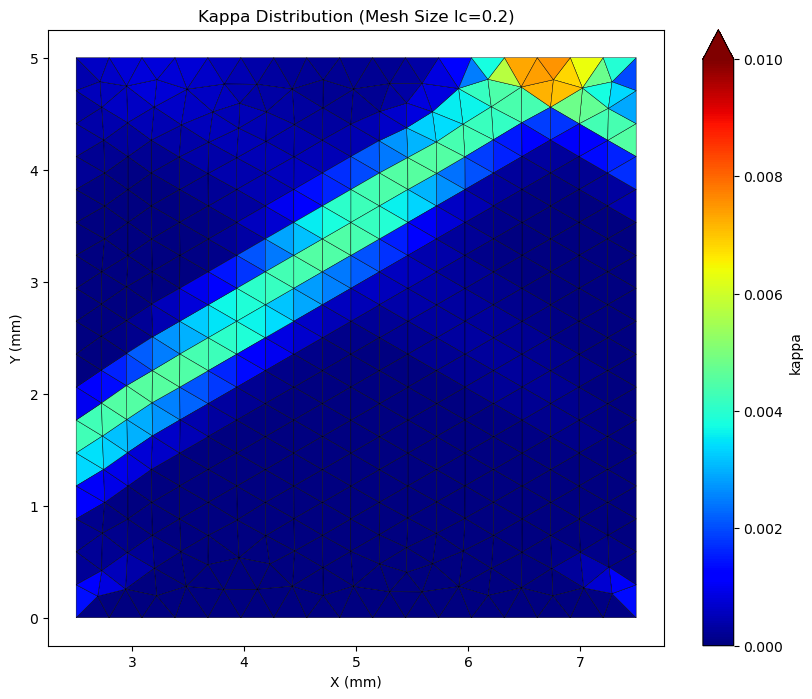

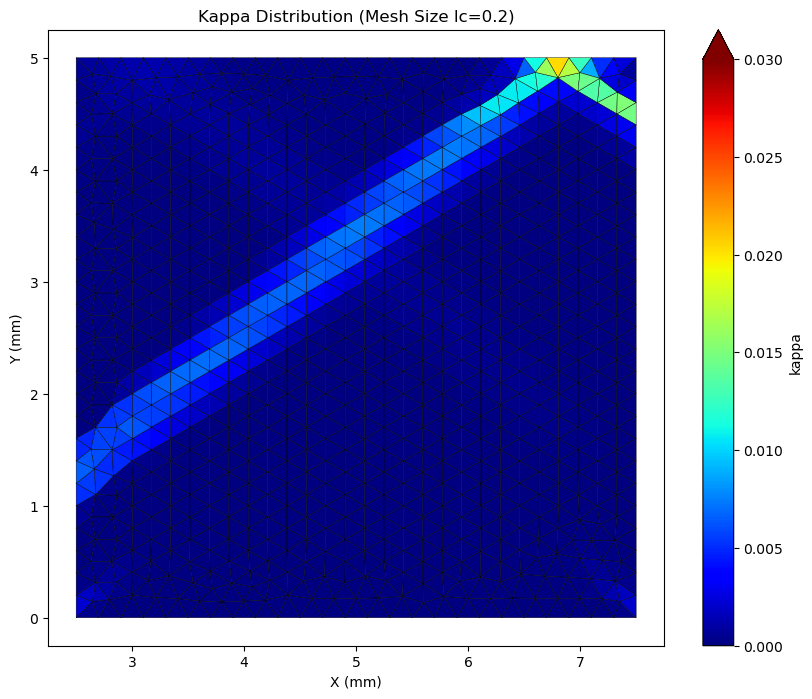

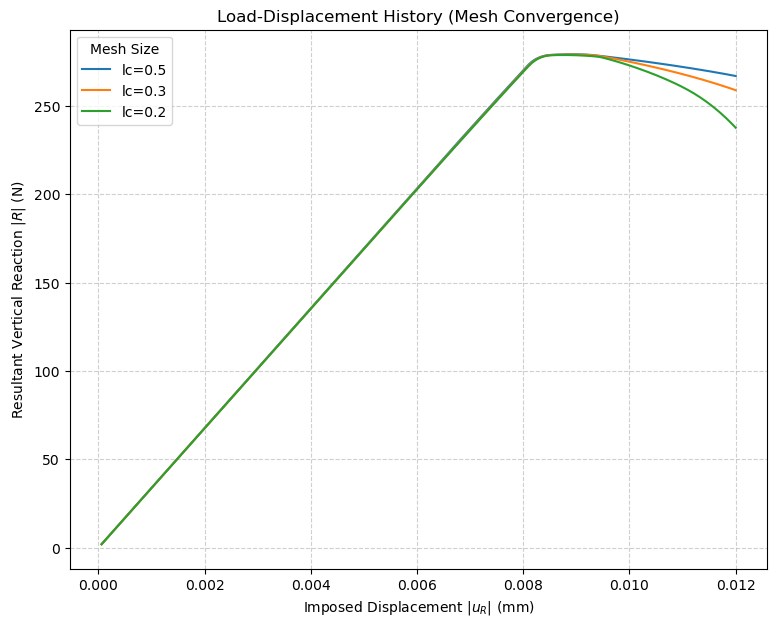

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as tri

def read_results_from_excel(lc_value):
    """Reads node, element, stress, and load-displacement data from a single Excel file."""
    filename = f"FEM_results_u0012_lc_{lc_value}.xlsx"
    try:
        # Read data from sheets
        df_nodes = pd.read_excel(filename, sheet_name="Nodes")
        df_elements = pd.read_excel(filename, sheet_name="Elements")
        df_vm = pd.read_excel(filename, sheet_name="Von_Mises")
        df_load_disp = pd.read_excel(filename, sheet_name="Load_Displacement")
        df_kappa = pd.read_excel(filename, sheet_name="Kappa")

        # Extract required arrays
        node_coords = df_nodes[['x', 'y']].values
        
        # Elements are stored as [n1, n2, n3]. Exclude the 'elem_id' column.
        elements_raw = df_elements[['n1', 'n2', 'n3']].values 
        
        von_mises = df_vm['von_mises'].values
        
        sum_du = df_load_disp['Imposed U'].values
        sum_R = df_load_disp['Resultant R'].values
        kappa = df_kappa['kappa'].values
        
        return {
            'lc': lc_value,
            'node_coords': node_coords,
            'elements': elements_raw,
            'von_mises': von_mises,
            'sum_du': sum_du,
            'sum_R': sum_R,
            'kappa': kappa
        }
    except FileNotFoundError:
        print(f"Error: File not found for lc={lc_value} at {filename}")
        return None
    


def plot_von_mises_field(result_data):
 
     if not result_data:
        return

     node_coords = result_data['node_coords']
     elements_raw = result_data['elements']
     von_mises = result_data['von_mises']
     lc = result_data['lc']
    
    # Adjust element indices for zero-based indexing in matplotlib
     elements_adjusted = elements_raw - 1

    # Create a triangulation object
     triang = tri.Triangulation(node_coords[:, 0], node_coords[:, 1], elements_adjusted)

    # Plot the stress distribution
     plt.figure(figsize=(10, 8))
    
    # Use tripcolor to fill the triangles with the element stress value
    # The number of facecolors must match the number of triangles
     plt.tripcolor(triang, facecolors=von_mises, edgecolors='k', cmap='jet', linewidth=0.5)
    
    # Calculate min/max for color bar uniformity (optional, but good practice)
     vmin = 0
     vmax = np.ceil(von_mises.max() / 10) * 10 # Round up to the nearest 10
    
     cbar = plt.colorbar(label='Equivalent Von Mises Stress (MPa)', extend='max')
     cbar.mappable.set_clim(vmin, vmax)
    
     plt.gca().set_aspect('equal')
     plt.title(f'Equivalent Von Mises Stress (Mesh Size lc={lc})')
     plt.xlabel('X (mm)')
     plt.ylabel('Y (mm)')
     plt.show()


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as tri

def plot_element_scalar_field(result_data, title_suffix):
    """
    Visualizes any scalar field (like Kappa or Von Mises Stress) across the mesh.
    """
    # Ensure element indices are zero-based for matplotlib
    elements_adjusted = result_data['elements'] - 1
    scalar_data= result_data['kappa']  # e.g., 'kappa' or 'von_mises'
    # Create a triangulation object
    triang = tri.Triangulation(result_data['node_coords'][:, 0], result_data['node_coords'][:, 1], elements_adjusted)

    plt.figure(figsize=(10, 8))
    
    # Plot the scalar field (e.g., Kappa or Von Mises)
    plt.tripcolor(triang, facecolors=scalar_data, edgecolors='k', cmap='jet', linewidth=0.3)
    
    # Set colorbar dynamically: Kappa typically ranges from 0 up to a small value (e.g., 0.01)
    if scalar_data.max() > 1e-6:
        # If there is meaningful plastic strain, set max scale
        vmax = np.ceil(scalar_data.max() * 100) / 100 
    else:
        vmax = 1e-4 # Use a small default if no plastic strain occurred yet

    cbar = plt.colorbar(label='kappa', extend='max')
    cbar.mappable.set_clim(0, vmax)
    
    plt.gca().set_aspect('equal')
    plt.title(f'{title_suffix} Distribution (Mesh Size lc={lc})')
    plt.xlabel('X (mm)')
    plt.ylabel('Y (mm)')
    plt.show()

# --- Example of Reading Data and Plotting Kappa ---




def plot_load_displacement_history(all_results):
    """
    Plots the Load-Displacement curve for all mesh sizes on one graph.
    """
    plt.figure(figsize=(9, 7))
    plt.title('Load-Displacement History (Mesh Convergence)')
    plt.xlabel('Imposed Displacement $|u_R|$ (mm)')
    plt.ylabel('Resultant Vertical Reaction $|R|$ (N)')

    for data in all_results:
        if data:
            # We plot the absolute values as displacement is negative (downwards)
            plt.plot(np.abs(data['sum_du']), np.abs(data['sum_R']), 
                     label=f'lc={data["lc"]}', linewidth=1.5)

    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(title="Mesh Size")
    plt.show()




    # --- EXECUTION ---

# List of mesh sizes you want to analyze (must correspond to generated Excel files)
lc_values = [0.5, 0.3, 0.2] 

all_results_data = []

# 1. Read and store data for each mesh size
for lc in lc_values:
    data = read_results_from_excel(lc)
    if data:
        all_results_data.append(data)

# 2. Plotting

# Plot Von Mises field for each mesh size individually
for data in all_results_data:
    plot_von_mises_field(data)
    

# Plot kappa field for each mesh size individually
for data in all_results_data:
    
    plot_element_scalar_field(data, title_suffix="Kappa")


# Plot all Load-Displacement curves on one comparison graph
plot_load_displacement_history(all_results_data)

PLOT RESULTS FOR HARDENING AND DISPLACEMENT 0.012 mm

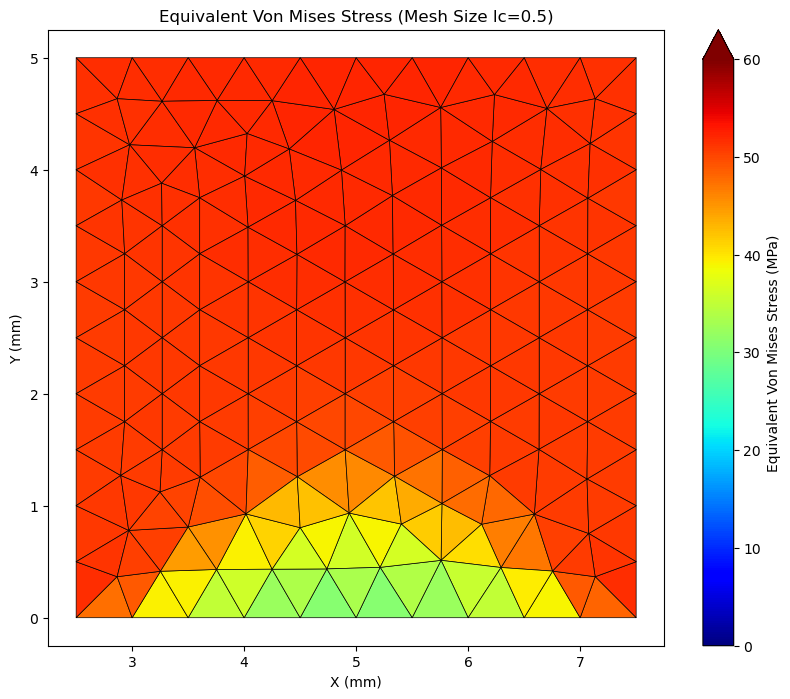

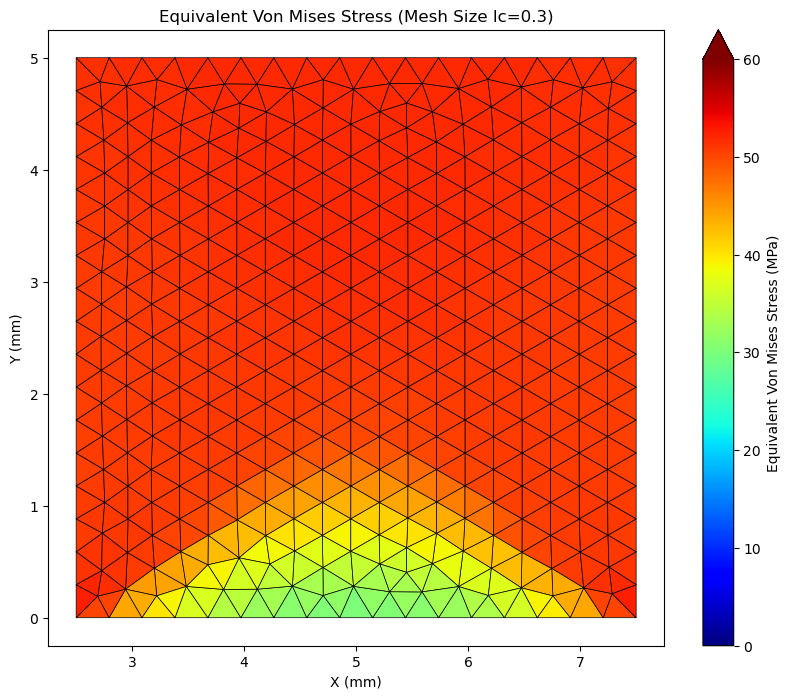

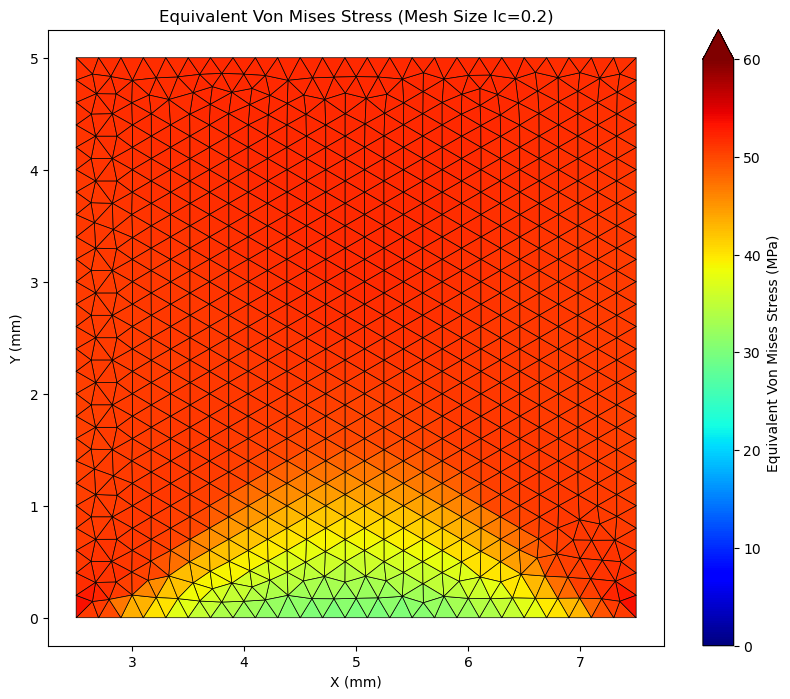

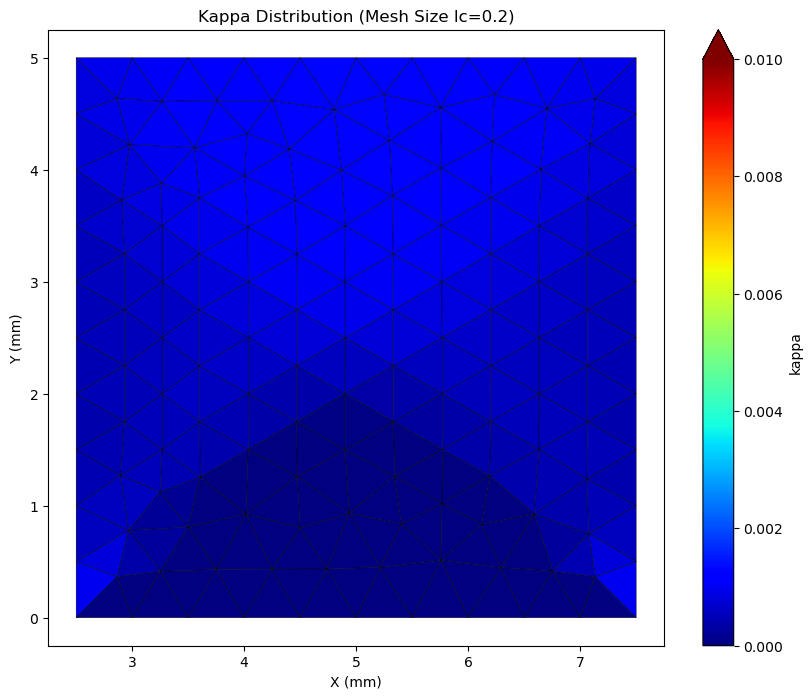

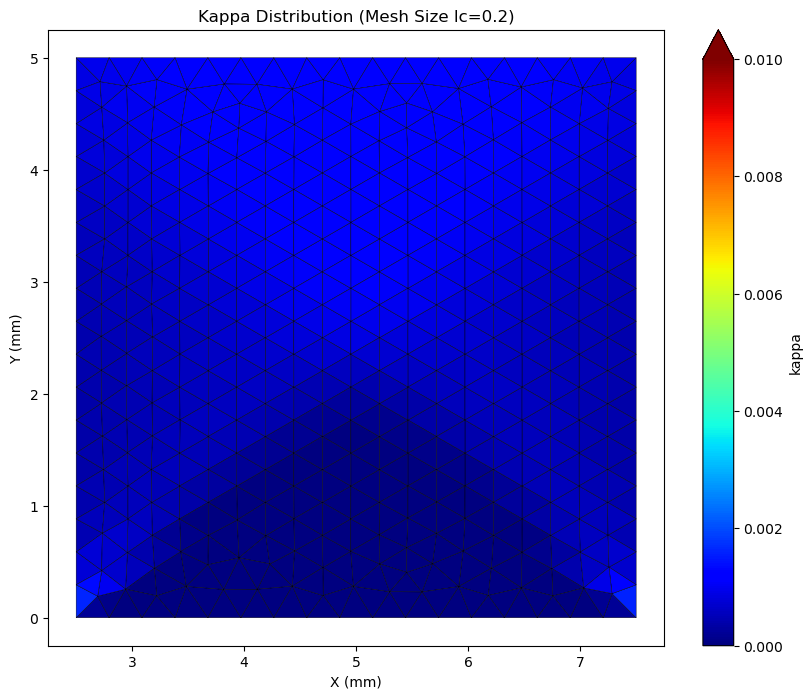

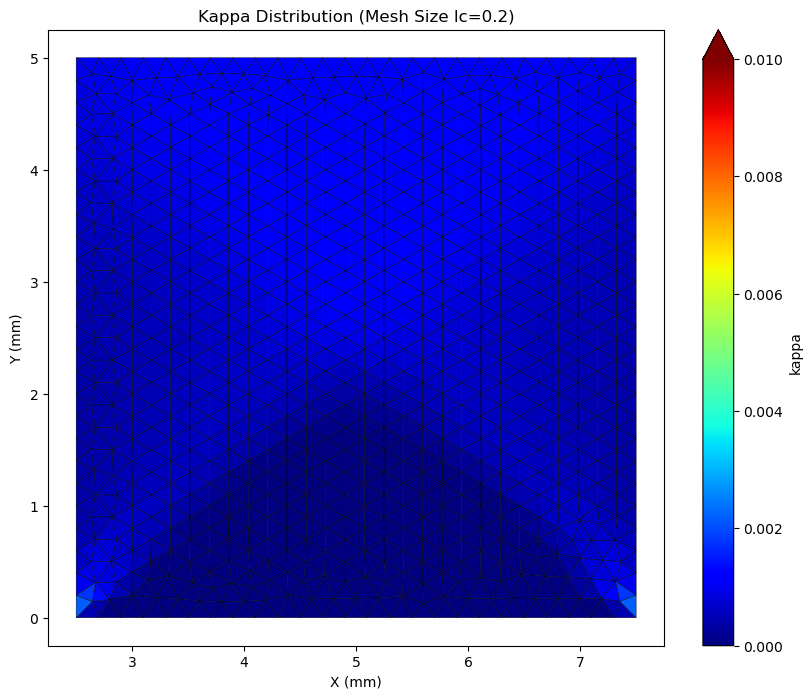

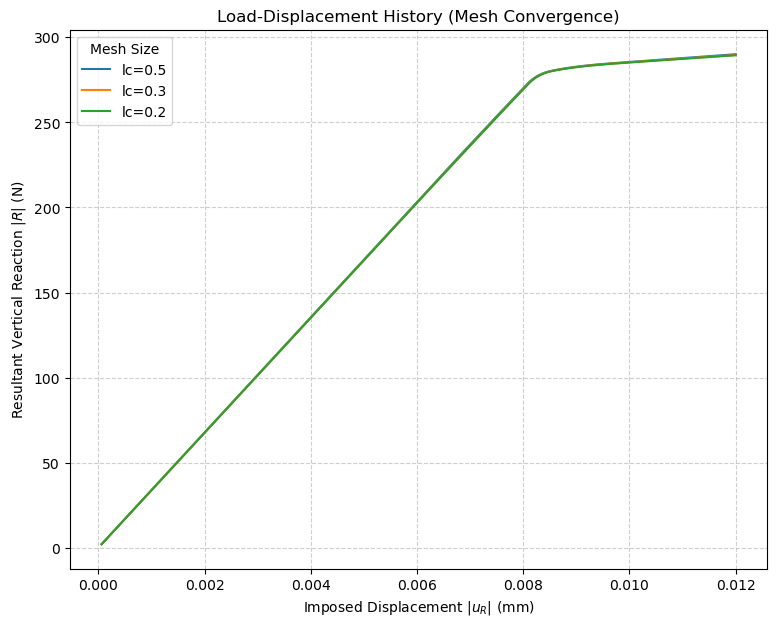

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as tri


def read_results_from_excel(lc_value):
    """Reads node, element, stress, and load-displacement data from a single Excel file."""
    filename = f"FEM_results_u0012_hardening_lc_{lc_value}.xlsx"
    try:
        # Read data from sheets
        df_nodes = pd.read_excel(filename, sheet_name="Nodes")
        df_elements = pd.read_excel(filename, sheet_name="Elements")
        df_vm = pd.read_excel(filename, sheet_name="Von_Mises")
        df_load_disp = pd.read_excel(filename, sheet_name="Load_Displacement")
        df_kappa = pd.read_excel(filename, sheet_name="Kappa")

        # Extract required arrays
        node_coords = df_nodes[['x', 'y']].values
        
        # Elements are stored as [n1, n2, n3]. Exclude the 'elem_id' column.
        elements_raw = df_elements[['n1', 'n2', 'n3']].values 
        
        von_mises = df_vm['von_mises'].values
        
        sum_du = df_load_disp['Imposed U'].values
        sum_R = df_load_disp['Resultant R'].values
        kappa = df_kappa['kappa'].values
        
        return {
            'lc': lc_value,
            'node_coords': node_coords,
            'elements': elements_raw,
            'von_mises': von_mises,
            'sum_du': sum_du,
            'sum_R': sum_R,
            'kappa': kappa
        }
    except FileNotFoundError:
        print(f"Error: File not found for lc={lc_value} at {filename}")
        return None
    


def plot_von_mises_field(result_data):
 
     if not result_data:
        return

     node_coords = result_data['node_coords']
     elements_raw = result_data['elements']
     von_mises = result_data['von_mises']
     lc = result_data['lc']
    
    # Adjust element indices for zero-based indexing in matplotlib
     elements_adjusted = elements_raw - 1

    # Create a triangulation object
     triang = tri.Triangulation(node_coords[:, 0], node_coords[:, 1], elements_adjusted)

    # Plot the stress distribution
     plt.figure(figsize=(10, 8))
    
    # Use tripcolor to fill the triangles with the element stress value
    # The number of facecolors must match the number of triangles
     plt.tripcolor(triang, facecolors=von_mises, edgecolors='k', cmap='jet', linewidth=0.5)
    
    # Calculate min/max for color bar uniformity (optional, but good practice)
     vmin = 0
     vmax = np.ceil(von_mises.max() / 10) * 10 # Round up to the nearest 10
    
     cbar = plt.colorbar(label='Equivalent Von Mises Stress (MPa)', extend='max')
     cbar.mappable.set_clim(vmin, vmax)
    
     plt.gca().set_aspect('equal')
     plt.title(f'Equivalent Von Mises Stress (Mesh Size lc={lc})')
     plt.xlabel('X (mm)')
     plt.ylabel('Y (mm)')
     plt.show()




def plot_element_scalar_field(result_data, title_suffix):
    """
    Visualizes any scalar field (like Kappa or Von Mises Stress) across the mesh.
    """
    # Ensure element indices are zero-based for matplotlib
    elements_adjusted = result_data['elements'] - 1
    scalar_data= result_data['kappa']  # e.g., 'kappa' or 'von_mises'
    # Create a triangulation object
    triang = tri.Triangulation(result_data['node_coords'][:, 0], result_data['node_coords'][:, 1], elements_adjusted)

    plt.figure(figsize=(10, 8))
    
    # Plot the scalar field (e.g., Kappa or Von Mises)
    plt.tripcolor(triang, facecolors=scalar_data, edgecolors='k', cmap='jet', linewidth=0.3)
    
    # Set colorbar dynamically: Kappa typically ranges from 0 up to a small value (e.g., 0.01)
    if scalar_data.max() > 1e-6:
        # If there is meaningful plastic strain, set max scale
        vmax = np.ceil(scalar_data.max() * 100) / 100 
    else:
        vmax = 1e-4 # Use a small default if no plastic strain occurred yet

    cbar = plt.colorbar(label='kappa', extend='max')
    cbar.mappable.set_clim(0, vmax)
    
    plt.gca().set_aspect('equal')
    plt.title(f'{title_suffix} Distribution (Mesh Size lc={lc})')
    plt.xlabel('X (mm)')
    plt.ylabel('Y (mm)')
    plt.show()

# --- Example of Reading Data and Plotting Kappa ---




def plot_load_displacement_history(all_results):
    """
    Plots the Load-Displacement curve for all mesh sizes on one graph.
    """
    plt.figure(figsize=(9, 7))
    plt.title('Load-Displacement History (Mesh Convergence)')
    plt.xlabel('Imposed Displacement $|u_R|$ (mm)')
    plt.ylabel('Resultant Vertical Reaction $|R|$ (N)')

    for data in all_results:
        if data:
            # We plot the absolute values as displacement is negative (downwards)
            plt.plot(np.abs(data['sum_du']), np.abs(data['sum_R']), 
                     label=f'lc={data["lc"]}', linewidth=1.5)

    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(title="Mesh Size")
    plt.show()




    # --- EXECUTION ---

# List of mesh sizes you want to analyze (must correspond to generated Excel files)
lc_values = [0.5, 0.3, 0.2] 

all_results_data = []

# 1. Read and store data for each mesh size
for lc in lc_values:
    data = read_results_from_excel(lc)
    if data:
        all_results_data.append(data)

# 2. Plotting

# Plot Von Mises field for each mesh size individually
for data in all_results_data:
    plot_von_mises_field(data)
    

# Plot kappa field for each mesh size individually
for data in all_results_data:
    
    plot_element_scalar_field(data, title_suffix="Kappa")


# Plot all Load-Displacement curves on one comparison graph
plot_load_displacement_history(all_results_data)

RESULTS FOR DISPLACEMENT 0.015 

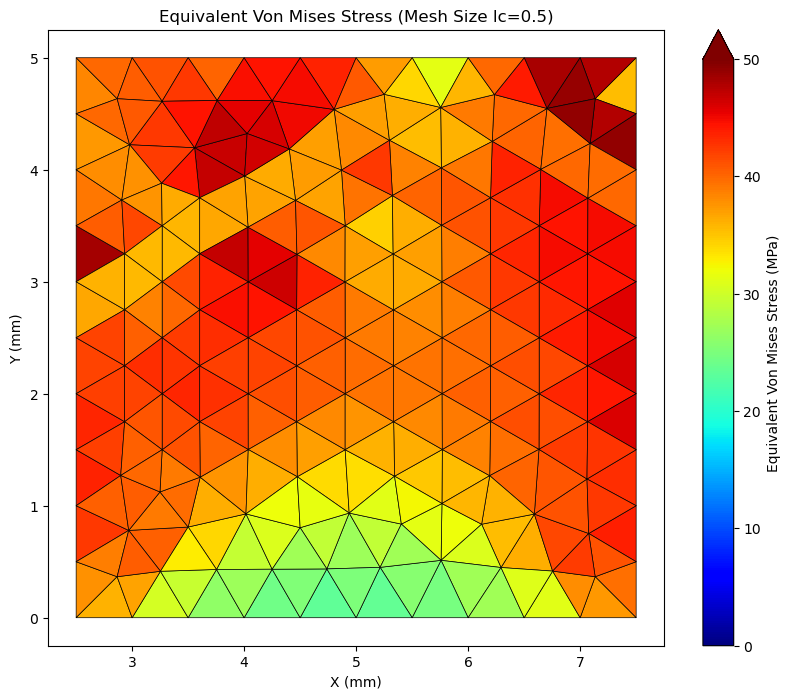

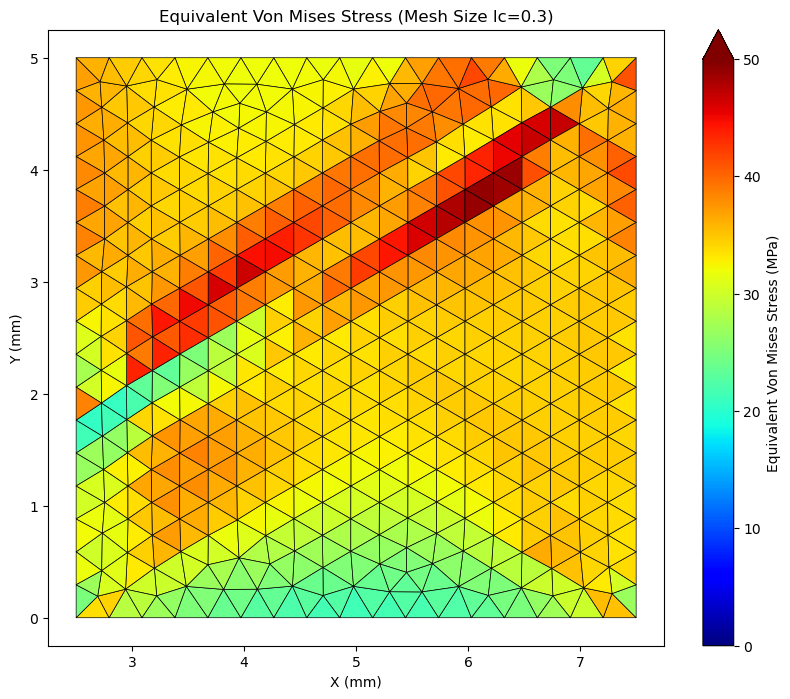

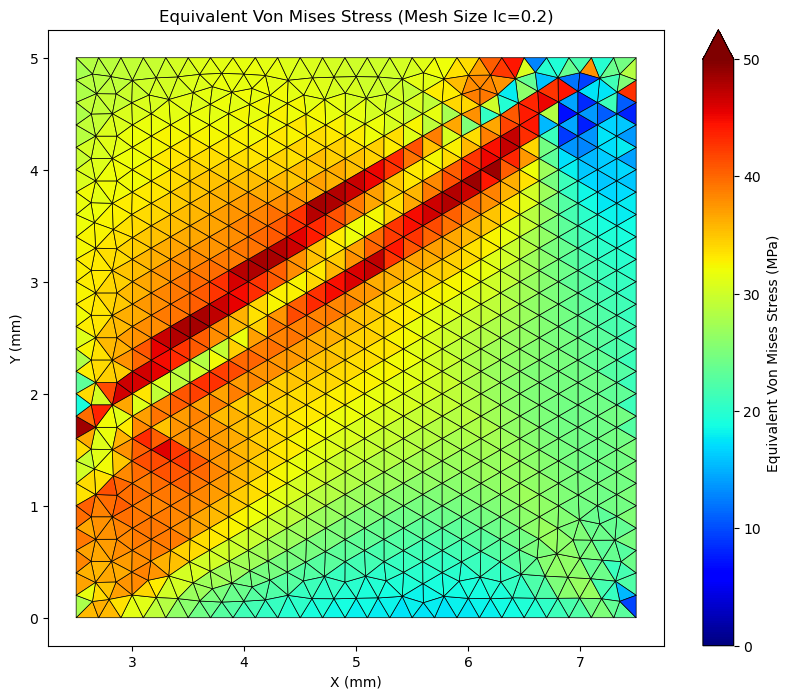

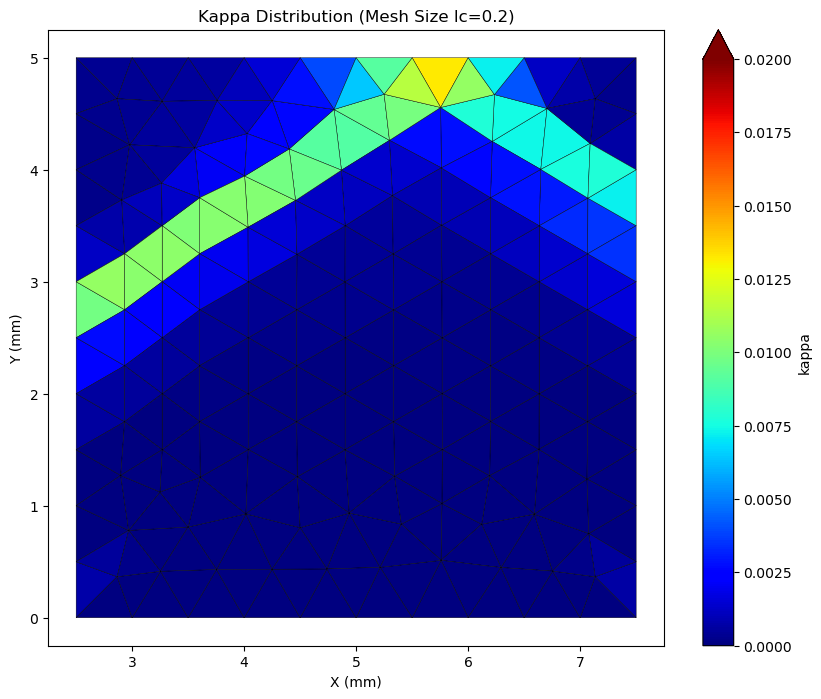

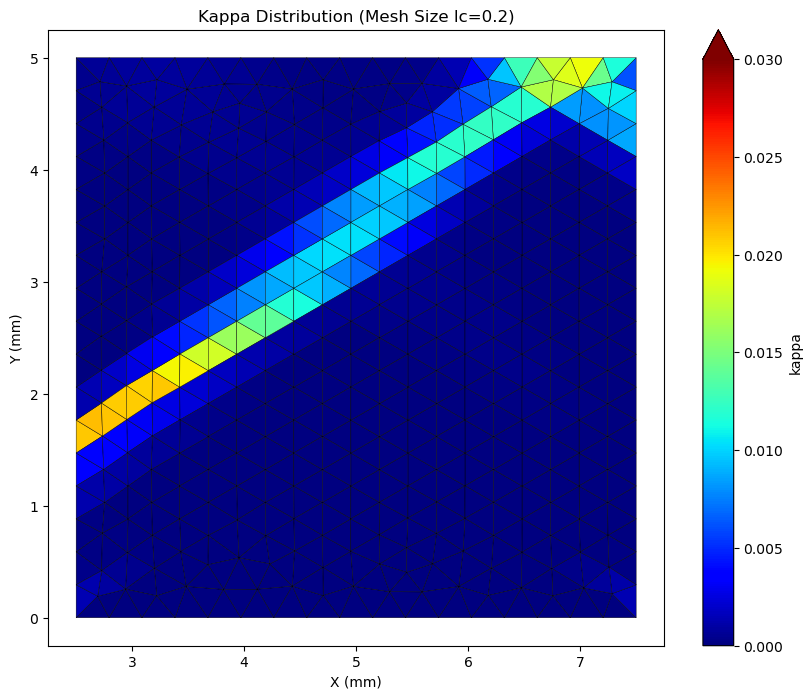

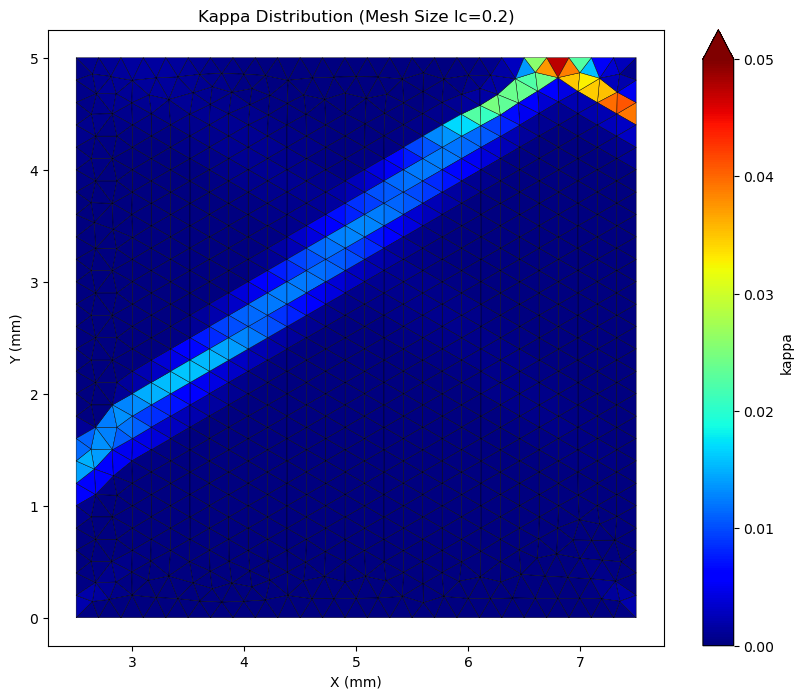

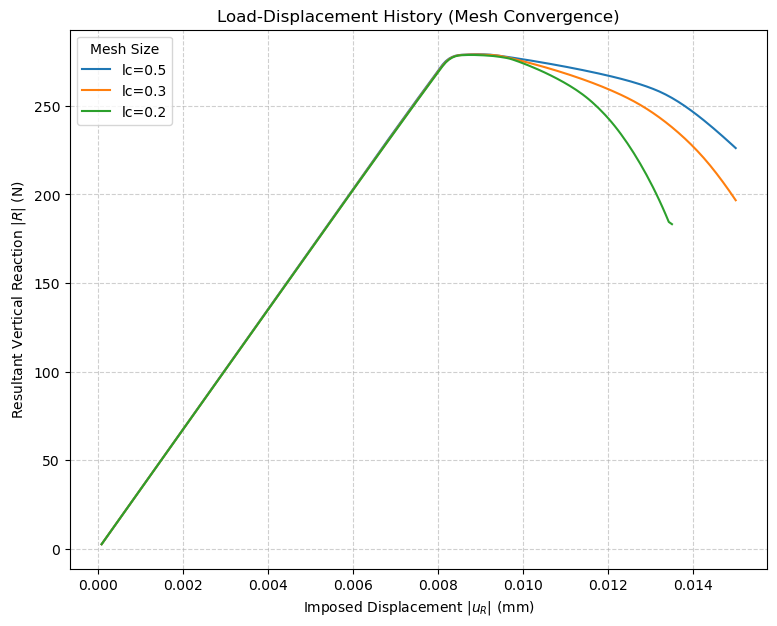

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as tri


def read_results_from_excel(lc_value):
    """Reads node, element, stress, and load-displacement data from a single Excel file."""
    filename = f"FEM_results_lc_{lc_value}.xlsx"
    try:
        # Read data from sheets
        df_nodes = pd.read_excel(filename, sheet_name="Nodes")
        df_elements = pd.read_excel(filename, sheet_name="Elements")
        df_vm = pd.read_excel(filename, sheet_name="Von_Mises")
        df_load_disp = pd.read_excel(filename, sheet_name="Load_Displacement")
        df_kappa = pd.read_excel(filename, sheet_name="Kappa")

        # Extract required arrays
        node_coords = df_nodes[['x', 'y']].values
        
        # Elements are stored as [n1, n2, n3]. Exclude the 'elem_id' column.
        elements_raw = df_elements[['n1', 'n2', 'n3']].values 
        
        von_mises = df_vm['von_mises'].values
        
        sum_du = df_load_disp['Imposed U'].values
        sum_R = df_load_disp['Resultant R'].values
        kappa = df_kappa['kappa'].values
        
        return {
            'lc': lc_value,
            'node_coords': node_coords,
            'elements': elements_raw,
            'von_mises': von_mises,
            'sum_du': sum_du,
            'sum_R': sum_R,
            'kappa': kappa
        }
    except FileNotFoundError:
        print(f"Error: File not found for lc={lc_value} at {filename}")
        return None
    


def plot_von_mises_field(result_data):
 
     if not result_data:
        return

     node_coords = result_data['node_coords']
     elements_raw = result_data['elements']
     von_mises = result_data['von_mises']
     lc = result_data['lc']
    
    # Adjust element indices for zero-based indexing in matplotlib
     elements_adjusted = elements_raw - 1

    # Create a triangulation object
     triang = tri.Triangulation(node_coords[:, 0], node_coords[:, 1], elements_adjusted)

    # Plot the stress distribution
     plt.figure(figsize=(10, 8))
    
    # Use tripcolor to fill the triangles with the element stress value
    # The number of facecolors must match the number of triangles
     plt.tripcolor(triang, facecolors=von_mises, edgecolors='k', cmap='jet', linewidth=0.5)
    
    # Calculate min/max for color bar uniformity (optional, but good practice)
     vmin = 0
     vmax = np.ceil(von_mises.max() / 10) * 10 # Round up to the nearest 10
    
     cbar = plt.colorbar(label='Equivalent Von Mises Stress (MPa)', extend='max')
     cbar.mappable.set_clim(vmin, vmax)
    
     plt.gca().set_aspect('equal')
     plt.title(f'Equivalent Von Mises Stress (Mesh Size lc={lc})')
     plt.xlabel('X (mm)')
     plt.ylabel('Y (mm)')
     plt.show()




def plot_element_scalar_field(result_data, title_suffix):
    """
    Visualizes any scalar field (like Kappa or Von Mises Stress) across the mesh.
    """
    # Ensure element indices are zero-based for matplotlib
    elements_adjusted = result_data['elements'] - 1
    scalar_data= result_data['kappa']  # e.g., 'kappa' or 'von_mises'
    # Create a triangulation object
    triang = tri.Triangulation(result_data['node_coords'][:, 0], result_data['node_coords'][:, 1], elements_adjusted)

    plt.figure(figsize=(10, 8))
    
    # Plot the scalar field (e.g., Kappa or Von Mises)
    plt.tripcolor(triang, facecolors=scalar_data, edgecolors='k', cmap='jet', linewidth=0.3)
    
    # Set colorbar dynamically: Kappa typically ranges from 0 up to a small value (e.g., 0.01)
    if scalar_data.max() > 1e-6:
        # If there is meaningful plastic strain, set max scale
        vmax = np.ceil(scalar_data.max() * 100) / 100 
    else:
        vmax = 1e-4 # Use a small default if no plastic strain occurred yet

    cbar = plt.colorbar(label='kappa', extend='max')
    cbar.mappable.set_clim(0, vmax)
    
    plt.gca().set_aspect('equal')
    plt.title(f'{title_suffix} Distribution (Mesh Size lc={lc})')
    plt.xlabel('X (mm)')
    plt.ylabel('Y (mm)')
    plt.show()

# --- Example of Reading Data and Plotting Kappa ---




def plot_load_displacement_history(all_results):
    """
    Plots the Load-Displacement curve for all mesh sizes on one graph.
    """
    plt.figure(figsize=(9, 7))
    plt.title('Load-Displacement History (Mesh Convergence)')
    plt.xlabel('Imposed Displacement $|u_R|$ (mm)')
    plt.ylabel('Resultant Vertical Reaction $|R|$ (N)')

    for data in all_results:
        if data:
            # We plot the absolute values as displacement is negative (downwards)
            plt.plot(np.abs(data['sum_du']), np.abs(data['sum_R']), 
                     label=f'lc={data["lc"]}', linewidth=1.5)

    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(title="Mesh Size")
    plt.show()




    # --- EXECUTION ---

# List of mesh sizes you want to analyze (must correspond to generated Excel files)
lc_values = [0.5, 0.3, 0.2] 

all_results_data = []

# 1. Read and store data for each mesh size
for lc in lc_values:
    data = read_results_from_excel(lc)
    if data:
        all_results_data.append(data)

# 2. Plotting

# Plot Von Mises field for each mesh size individually
for data in all_results_data:
    plot_von_mises_field(data)
    

# Plot kappa field for each mesh size individually
for data in all_results_data:
    
    plot_element_scalar_field(data, title_suffix="Kappa")


# Plot all Load-Displacement curves on one comparison graph
plot_load_displacement_history(all_results_data)